###  Cách triển khai mô hình hiện tại:
- Tuning sử dụng GridSearchCV để tìm ra parameter tốt nhất
- Sử dụng k-fold validate để tránh overfiting
- Chưa tối ưu ngưỡng phân loại (threshold)
- Áp dụng các kỹ thuật resampling như SMOTE để xử lý mất cân bằng cho toàn bộ model

SMOTE tạo dữ liệu mới bằng cách nội suy tuyến tính, điều này gây nhiễu cho mô hình cây như XGBoost, LightGBM, CatBoost, Random Forest.

==> Linear models (Logistic Regression) hưởng lợi rõ ràng hơn từ dữ liệu được cân bằng vì ranh giới quyết định tuyến tính rất nhạy cảm với tỷ lệ lớp ->F1

In [ ]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.8 MB/s eta 0:00:00


In [ ]:
# Import libraries
import os
import gc
from glob import glob
from pathlib import Path
from datetime import datetime

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns



from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, LabelEncoder
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from tqdm import tqdm
from sklearn.model_selection import ParameterGrid
from sklearn.model_selection import train_test_split, StratifiedGroupKFold, KFold, cross_val_predict, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, classification_report, roc_curve)

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier,StackingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
import catboost as cb
import lightgbm as lgb
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter
import copy
import warnings
import time
warnings.simplefilter(action='ignore', category=FutureWarning)
pd.set_option('display.max_columns', None)

import joblib

## Data Preprocessing

### Load data

In [ ]:
from google.colab import drive
root_drive='/content/drive'
drive.mount(root_drive, force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned_old_customers.csv', nrows=None)

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned.csv', nrows=None)

In [ ]:
df = df.drop(columns=['Unnamed: 0'])
print("Dữ liệu có dạng:", df.shape)
df.head()

Dữ liệu có dạng: (291057, 28)


,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,PREV_APP_CREDIT_PERC_MIN,INST_DPD_MEAN,INST_PAYMENT_DIFF_MEAN,INST_AMT_PAYMENT_MEAN,INST_AMT_INSTALMENT_MAX,POS_MONTHS_BALANCE_SIZE,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,AGE,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,24.0,1.000000,0.000000,0.00000,11559.247,53093.746,19.0,Business Entity,Single,26,25-34,10,6,2.0,1.0,2.4,1.4,1.7,0.1
1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,30.0,0.868825,0.000000,0.00000,64754.586,560835.400,28.0,Unknown,Married,46,45-54,3,1,3.0,1.5,3.8,2.2,2.0,1.5
2,0.0,0.6426,67500.0,135000.0,6750.0,0.0,94518.900,0.0000,5357.250,4.0,1.207699,0.000000,0.00000,7096.155,10573.965,4.0,Other,Single,52,45-54,12,7,1.0,1.3,2.4,1.5,2.2,2.0
3,0.0,0.6504,135000.0,312682.5,29686.5,44971.6,194400.000,0.0000,23651.174,138.0,0.759418,0.000000,0.00000,62947.090,691786.900,21.0,Business Entity,Married,52,45-54,27,7,8.0,0.4,2.9,1.3,0.5,0.0
4,0.0,0.3228,121500.0,513000.0,21865.5,0.0,146250.000,0.0000,12278.805,124.0,0.791139,0.954545,452.38434,12214.060,22678.785,66.0,Culture & Religion,Single,55,55-64,12,9,8.0,2.1,3.1,2.1,1.0,0.0


### Split tập train/test trước khi xử lý dữ liệu

In [ ]:
# Tách X, y
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Train-test split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [ ]:
y_train.value_counts()

,count
TARGET,
0.0,213769
1.0,19076


### Feature pipeline

Chỉ tạo preprocessor và fit chỉ trên train

In [ ]:
# Chia cột
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# Tiền xử lý
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

In [ ]:
x_train_processed = preprocessor.fit_transform(X_train_raw)
x_test_processed = preprocessor.transform(X_test_raw)

## Machine Learning - Modeling

Evaluate Function

In [ ]:
def gini_score(y_true, y_proba):
    return 2 * roc_auc_score(y_true, y_proba) - 1

def evaluate_model(model, X_test, y_test, model_name=None, verbose=True):
    start = time.time()
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else y_pred
    end = time.time()

    cm = confusion_matrix(y_test, y_pred)
    TN, FP, FN, TP = cm.ravel()

    recall = TP / (TP + FN) if (TP + FN) > 0 else 0  # Sensitivity
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    gmean = np.sqrt(recall * specificity)
    auc = roc_auc_score(y_test, y_proba)
    gini = 2 * auc - 1

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "Recall (Sensitivity)": recall,
        "Specificity": specificity,
        "G-Mean": gmean,
        "ROC AUC": auc,
        "Gini": gini,
        "Time": round(end - start, 2)
    }

    if verbose:
        print(f"\n Evaluation for {model_name or 'model'}")
        print(f"Accuracy       : {results['Accuracy']:.4f}")
        print(f"F1-score       : {results['F1']:.4f}")
        print(f"Recall         : {results['Recall (Sensitivity)']:.4f}")
        print(f"Specificity    : {results['Specificity']:.4f}")
        print(f"G-Mean         : {results['G-Mean']:.4f}")
        print(f"ROC AUC        : {results['ROC AUC']:.4f}")
        print(f"Gini           : {results['Gini']:.4f}")
        print("Confusion Matrix:\n", cm)
        print("Classification Report:\n", classification_report(y_test, y_pred))
        print(f"Time taken: {results['Time']}s\n")

    return results


In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier # Import XGBClassifier to check type
from catboost import CatBoostClassifier # Import CatBoostClassifier to check type
from lightgbm import LGBMClassifier # Import LGBMClassifier to check type

def train_model_with_cv(X, y, model, model_name, preprocessor,imbalance_strategy,
                        k=5, random_state=42):
    print(f"\nTraining: {model_name}")
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=random_state)
    scores = []
    best_score = -np.inf
    best_model = None

    for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
        print(f"\nFold {fold+1}/{k}")
        X_train, y_train_fold = X.iloc[train_idx], y.iloc[train_idx]
        X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]

        # Preprocessing
        if imbalance_strategy == "smote":
            sampler = SMOTE(random_state=random_state)
        elif imbalance_strategy == "under":
            sampler = RandomUnderSampler(random_state=random_state)
        else:
            sampler = "passthrough"

        # Clone model để tránh lặp lại trạng thái
        import copy
        model_copy = copy.deepcopy(model)

        # Initialize an empty fit_params dictionary
        fit_params = {}

        # Create the pipeline
        pipeline = ImbPipeline(steps=[
            ("preprocessor", preprocessor),
            ("sampler", sampler),
            ("classifier", model_copy)
        ])

        # Apply preprocessor to training data before fitting the pipeline if SMOTE is used
        if imbalance_strategy == "smote":
             X_train_processed = preprocessor.transform(X_train)
             X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_processed, y_train_fold)
             # Fit only the classifier on the resampled data
             # Pass any relevant fit_params to the classifier (currently none are added here)
             pipeline.named_steps['classifier'].fit(X_train_resampled, y_train_resampled)
        else:
            # Fit the entire pipeline
            pipeline.fit(X_train, y_train_fold, **fit_params)


        y_val_proba = pipeline.predict_proba(X_val)[:, 1]
        gini = 2 * roc_auc_score(y_val, y_val_proba) - 1 # Use Gini score directly

        scores.append(gini)

        if gini > best_score:
            best_score = gini
            best_model = pipeline

        print(f"Fold {fold+1} Gini: {gini:.4f}")

    print(f"\n {model_name} - Mean Gini: {np.mean(scores):.4f}")
    return best_model

RandomUnderSampler

In [ ]:
# Mô hình mẫu
xgb = XGBClassifier(
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    n_estimators=200,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.05,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42)
xgb_best_model = train_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model= xgb,
    model_name="XGBoost",
    preprocessor=preprocessor,
    imbalance_strategy="under",
    k=5,
    random_state=42
)
xgb_result = evaluate_model(xgb_best_model, X_test_raw, y_test, model_name="XGBoost")



Training: XGBoost

Fold 1/5
Fold 1 Gini: 0.4945

Fold 2/5
Fold 2 Gini: 0.5068

Fold 3/5
Fold 3 Gini: 0.4992

Fold 4/5
Fold 4 Gini: 0.4880

Fold 5/5
Fold 5 Gini: 0.5003

 XGBoost - Mean Gini: 0.4978

 Evaluation for XGBoost
Accuracy       : 0.1465
F1-score       : 0.1595
Recall         : 0.9887
Specificity    : 0.0713
G-Mean         : 0.2656
ROC AUC        : 0.7485
Gini           : 0.4971
Confusion Matrix:
 [[ 3813 49630]
 [   54  4715]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.99      0.07      0.13     53443
         1.0       0.09      0.99      0.16      4769

    accuracy                           0.15     58212
   macro avg       0.54      0.53      0.15     58212
weighted avg       0.91      0.15      0.14     58212

Time taken: 2.49s



SMOTE

In [ ]:
# Mô hình mẫu
xgb = XGBClassifier(
    scale_pos_weight=len(y_train[y_train == 0]) / len(y_train[y_train == 1]),
    n_estimators=200,
    max_depth=6,
    subsample=0.8,
    learning_rate=0.05,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42)
xgb_best_model = train_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model= xgb,
    model_name="XGBoost",
    preprocessor=preprocessor,
    imbalance_strategy="smote",
    k=5,
    random_state=42
)
xgb_result = evaluate_model(xgb_best_model, X_test_raw, y_test, model_name="XGBoost")



Training: XGBoost

Fold 1/5
Fold 1 Gini: 0.4382

Fold 2/5
Fold 2 Gini: 0.4349

Fold 3/5
Fold 3 Gini: 0.4369

Fold 4/5
Fold 4 Gini: 0.4263

Fold 5/5
Fold 5 Gini: 0.4424

 XGBoost - Mean Gini: 0.4357

 Evaluation for XGBoost
Accuracy       : 0.5151
F1-score       : 0.2129
Recall         : 0.8004
Specificity    : 0.4897
G-Mean         : 0.6260
ROC AUC        : 0.7205
Gini           : 0.4409
Confusion Matrix:
 [[26170 27273]
 [  952  3817]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.49      0.65     53443
         1.0       0.12      0.80      0.21      4769

    accuracy                           0.52     58212
   macro avg       0.54      0.65      0.43     58212
weighted avg       0.90      0.52      0.61     58212

Time taken: 0.66s



## Machine Learning - Hyperparameter Tuning

In [ ]:
save_dir = "/content/drive/MyDrive/KhoaLuan/Models"
os.makedirs(save_dir, exist_ok=True)

In [ ]:
def tune_model_with_cv(X, y, model, model_name, preprocessor,
                       param_grid=None,
                       imbalance_strategy="smote",
                       search_method="grid",
                       k=5, n_iter=10):

    print(f"\n Tuning {model_name} using {search_method} search...")

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    # Xử lý sampling
    if imbalance_strategy == "smote":
        sampler = SMOTE(random_state=42)
    elif imbalance_strategy == "under":
        sampler = RandomUnderSampler(random_state=42)
    else:
        sampler = "passthrough"

    # Early stopping eval_set
    fit_params = {}
    # Note: Early stopping in pipelines can be tricky, especially with resampling.
    # We will add these parameters to the fit_params to be passed to pipeline.fit
    # But the actual handling depends on the pipeline and estimator implementations.
    # Based on previous errors, let's exclude early stopping from tune_model_with_cv for now
    # if model_name in ["xgb", "lgbm", "catboost"]:
    #     fit_params = {
    #         "classifier__early_stopping_rounds": 20,
    #         "classifier__eval_metric": "auc",
    #         "classifier__eval_set": [(preprocessor.fit_transform(X), y)],
    #         "classifier__verbose": False
    #     }

    model_clone = copy.deepcopy(model)

    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("sampler", sampler),
        ("classifier", model_clone)
    ])

    if param_grid:
        if search_method == "grid":
            search = GridSearchCV(
                pipeline, param_grid,
                scoring="roc_auc",
                cv=skf, n_jobs=-1, verbose=1
            )
        elif search_method == "random":
            search = RandomizedSearchCV(
                pipeline, param_distributions=param_grid,
                n_iter=n_iter, scoring="roc_auc",
                cv=skf, n_jobs=-1, verbose=1,
                random_state=42
            )
        # Fit
        # Pass fit_params if not empty, otherwise just fit without it
        if fit_params:
             search.fit(X, y, **fit_params)
        else:
             search.fit(X, y)


        print(f"Best ROC AUC score: {search.best_score_:.4f}")
        print("Best Parameters:", search.best_params_)

        # Return the best fitted estimator (the pipeline with best params)
        return search.best_estimator_
    else:
        # No tuning, just train the pipeline
        # Pass fit_params if not empty, otherwise just fit without it
        if fit_params:
            pipeline.fit(X, y, **fit_params)
        else:
            pipeline.fit(X, y)

        return pipeline # Return the fitted pipeline

### Logistic Regression

In [ ]:
%%time
# 1. Define model + params
logreg_model = LogisticRegression(solver='liblinear', class_weight='balanced', random_state=42)
# Correct the parameter grid name
logreg_param_grid = {'classifier__C': [0.1, 1, 10]}

# 2. Train
logreg_best_model= tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=logreg_model,
    model_name="Logistic Regression",
    preprocessor=preprocessor,
    param_grid=logreg_param_grid,
    imbalance_strategy="smote",
    search_method="grid",
    n_iter=10
)



 Tuning Logistic Regression using grid search...
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best ROC AUC score: 0.7323
Best Parameters: {'classifier__C': 0.1}
CPU times: user 1min 13s, sys: 1.05 s, total: 1min 14s
Wall time: 2min 53s


In [ ]:
# 3. Evaluate on test set
logreg_result = evaluate_model(logreg_best_model, X_test_raw, y_test, model_name="Logistic Regression")

joblib.dump(logreg_best_model, os.path.join(save_dir, "logreg_best_model.pkl"))


 Evaluation for Logistic Regression
Accuracy       : 0.6762
F1-score       : 0.2517
Recall         : 0.6647
Specificity    : 0.6773
G-Mean         : 0.6710
ROC AUC        : 0.7303
Gini           : 0.4605
Confusion Matrix:
 [[36195 17248]
 [ 1599  3170]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.96      0.68      0.79     53443
         1.0       0.16      0.66      0.25      4769

    accuracy                           0.68     58212
   macro avg       0.56      0.67      0.52     58212
weighted avg       0.89      0.68      0.75     58212

Time taken: 0.23s



['/content/drive/MyDrive/KhoaLuan/Models/logreg_best_model.pkl']

### Random Forest

In [ ]:
%%time
# 1. Khởi tạo mô hình Random Forest
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42)

# 2. GridSearchCV parameter grid
# Correct the parameter grid names to use 'classifier__' prefix
rf_param_grid = {
    'classifier__n_estimators': [150, 200, 250],
    'classifier__max_depth': [7, 10],
}

# 3. Chạy GridSearchCV
rf_best_model = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=rf_model,
    model_name="Random Forest",
    preprocessor=preprocessor,
    param_grid=rf_param_grid,
    imbalance_strategy="smote",
    search_method="grid",
    n_iter=10
)

# 4. Đánh giá
results_rf = evaluate_model(rf_best_model, X_test_raw, y_test, model_name="Random Forest")

# 5. Save model
joblib.dump(rf_best_model, os.path.join(save_dir, "rf_best_model.pkl"))


 Tuning Random Forest using grid search...
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best ROC AUC score: 0.6972
Best Parameters: {'classifier__max_depth': 10, 'classifier__n_estimators': 250}

 Evaluation for Random Forest
Accuracy       : 0.7738
F1-score       : 0.2444
Recall         : 0.4464
Specificity    : 0.8030
G-Mean         : 0.5987
ROC AUC        : 0.6974
Gini           : 0.3948
Confusion Matrix:
 [[42916 10527]
 [ 2640  2129]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.94      0.80      0.87     53443
         1.0       0.17      0.45      0.24      4769

    accuracy                           0.77     58212
   macro avg       0.56      0.62      0.56     58212
weighted avg       0.88      0.77      0.82     58212

Time taken: 6.31s

CPU times: user 1h 7min 6s, sys: 28.1 s, total: 1h 7min 35s
Wall time: 2h 22min 44s


['/content/drive/MyDrive/KhoaLuan/Models/rf_best_model.pkl']

### XGBoost

In [ ]:
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric="auc", random_state=42)

xgb_param_grid = {
    "classifier__n_estimators": [200, 300, 400],
    "classifier__max_depth": [5, 6, 7],
    "classifier__learning_rate": [0.01, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 1.0]
}

best_xgb_model = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=xgb_model,
    model_name="xgb",
    preprocessor=preprocessor,
    param_grid=xgb_param_grid,
    imbalance_strategy="smote",
    search_method="random",  # hoặc "grid"
    n_iter=10
)

# Đánh giá
results_xgb = evaluate_model(best_xgb_model, X_test_raw, y_test, model_name="xgb")

# Save model
joblib.dump(best_xgb_model, os.path.join(save_dir, "xgb_best_model.pkl"))


 Tuning xgb using random search...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best ROC AUC score: 0.7369
Best Parameters: {'classifier__subsample': 0.8, 'classifier__n_estimators': 400, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.1}

 Evaluation for xgb
Accuracy       : 0.9171
F1-score       : 0.0730
Recall         : 0.0398
Specificity    : 0.9954
G-Mean         : 0.1991
ROC AUC        : 0.7416
Gini           : 0.4832
Confusion Matrix:
 [[53199   244]
 [ 4579   190]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      1.00      0.96     53443
         1.0       0.44      0.04      0.07      4769

    accuracy                           0.92     58212
   macro avg       0.68      0.52      0.51     58212
weighted avg       0.88      0.92      0.88     58212

Time taken: 1.37s



['/content/drive/MyDrive/KhoaLuan/Models/xgb_best_model.pkl']

### LightGBM

In [ ]:
%%time
# 1. Pipeline cho LightGBM
lgbm_model = LGBMClassifier(
    objective='binary',
    boosting_type='gbdt',
    class_weight=None,
    random_state=42
)
# 2. GridSearchCV parameter grid cho lightGBM
lgbm_param_grid = {
    'classifier__n_estimators': [200, 300, 400], # default: 100
    'classifier__learning_rate': [0.01, 0.05, 0.1],  # default: 0.1
    'classifier__num_leaves': [31, 63, 127],  # default: 256
    'classifier__max_depth': [8, 10], # default: 8
}
# 3. Chạy GridSearchCV + đánh giá
lgbm_best_model = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=lgbm_model,
    model_name="LightGBM",
    preprocessor=preprocessor,
    param_grid=lgbm_param_grid,
    imbalance_strategy="smote",
    search_method="random",  # hoặc "grid"
    n_iter=10
)
lgbm_result = evaluate_model(lgbm_best_model, X_test_raw, y_test, "LightGBM")
joblib.dump(lgbm_best_model, os.path.join(save_dir, "lgbm_best_model.pkl"))


 Tuning LightGBM using random search...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
[LightGBM] [Info] Number of positive: 213769, number of negative: 213769
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.194482 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 11008
[LightGBM] [Info] Number of data points in the train set: 427538, number of used features: 44
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
Best ROC AUC score: 0.7393
Best Parameters: {'classifier__num_leaves': 31, 'classifier__n_estimators': 300, 'classifier__max_depth': 10, 'classifier__learning_rate': 0.1}

 Evaluation for LightGBM
Accuracy       : 0.9175
F1-score       : 0.0532
Recall         : 0.0283
Specificity    : 0.9969
G-Mean         : 0.1680
ROC AUC        : 0.7473
Gini           : 0.4946
Confusion Matrix:
 [[53275

['/content/drive/MyDrive/KhoaLuan/Models/lgbm_best_model.pkl']

### CatBoost

In [ ]:
%%time
# 1. Khởi tạo mô hình CatBoost
catboost_model = CatBoostClassifier(verbose=0, random_state=42)

# 2. GridSearchCV parameter grid cho CatBoost
# Correct the parameter grid names to use 'classifier__' prefix
catboost_param_grid = {
    'classifier__iterations': [100, 200, 300],
    'classifier__depth': [4, 6, 8],
    'classifier__learning_rate': [0.05, 0.1, 0.15]
}

# 3. Chạy GridSearchCV + đánh giá
catboost_best_model = tune_model_with_cv(
    X=X_train_raw,
    y=y_train,
    model=catboost_model,
    model_name="CatBoost",
    preprocessor=preprocessor,
    param_grid=catboost_param_grid,
    imbalance_strategy="smote",
    search_method="random",  # hoặc "grid"
    n_iter=10
)
catboost_result = evaluate_model(catboost_best_model, X_test_raw, y_test, "CatBoost")
joblib.dump(catboost_best_model, os.path.join(save_dir, "catboost_best_model.pkl"))


 Tuning CatBoost using random search...
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best ROC AUC score: 0.7469
Best Parameters: {'classifier__learning_rate': 0.15, 'classifier__iterations': 300, 'classifier__depth': 6}

 Evaluation for CatBoost
Accuracy       : 0.9184
F1-score       : 0.0546
Recall         : 0.0287
Specificity    : 0.9978
G-Mean         : 0.1693
ROC AUC        : 0.7518
Gini           : 0.5036
Confusion Matrix:
 [[53327   116]
 [ 4632   137]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      1.00      0.96     53443
         1.0       0.54      0.03      0.05      4769

    accuracy                           0.92     58212
   macro avg       0.73      0.51      0.51     58212
weighted avg       0.89      0.92      0.88     58212

Time taken: 2.08s

CPU times: user 10min, sys: 9.89 s, total: 10min 10s
Wall time: 39min 46s


['/content/drive/MyDrive/KhoaLuan/Models/catboost_best_model.pkl']

### Stacking LGBM, RF, and XGBoost with final estimator LR

In [ ]:
# Base models
base_learners_xgb = [
    ('lgbm', lgbm_model), # Use the raw LGBMClassifier
    ('rf', rf_model),     # Use the raw RandomForestClassifier
    ('xgb', xgb_model)      # Use the raw XGBClassifier
]

# Final estimator
final_estimator = LogisticRegression(
    solver='liblinear', class_weight='balanced', random_state=42)

# Stacking Classifier
stacking_lgbm_rf_xgb_model = StackingClassifier(
    estimators=base_learners_xgb,
    final_estimator=final_estimator,
    passthrough=False,
    n_jobs=-1
)

# Pipeline
stacking_lgbm_rf_xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('clf', stacking_lgbm_rf_xgb_model)
])

In [ ]:
%%time
# Fit & evaluate
stacking_lgbm_rf_xgb_pipeline.fit(X_train_raw, y_train)

CPU times: user 9min 4s, sys: 9.77 s, total: 9min 13s
Wall time: 31min 48s


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                                                               max_cat_threshold=None,
                                                               max_cat_to_onehot=None,
                                                               max_delta_step=None,
                                                               max_depth=None,
                                                               max_leaves=None,
                                                               min_child_weight=None,
                                                               missing=nan,
                                                               monotone_constraints=None,
                                                               multi_strategy=None,
                                                               n_estimators=None,
                                                               n_jobs=None,
                                                               num_parallel_tree=None,
                                                               random_state=42, ...))],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

In [ ]:
stacking_lgbm_rf_xgb_result = evaluate_model(
    model=stacking_lgbm_rf_xgb_pipeline,
    X_test=X_test_raw,
    y_test=y_test,
    model_name="Stacking_LGBM_RF_XGBoost"
)


 Evaluation for model
Accuracy       : 0.9023
F1-score       : 0.1733
Recall         : 0.1250
Specificity    : 0.9717
G-Mean         : 0.3485
ROC AUC        : 0.7205
Gini           : 0.4410
Confusion Matrix:
 [[51930  1513]
 [ 4173   596]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.97      0.95     53443
         1.0       0.28      0.12      0.17      4769

    accuracy                           0.90     58212
   macro avg       0.60      0.55      0.56     58212
weighted avg       0.87      0.90      0.88     58212

Time taken: 13.8s



###  Stacking LGBM, RF, and CatBoost with final estimator LR

In [ ]:
# Base models
# Use raw model estimators without preprocessing pipelines
base_learners_cat = [
    ('lgbm', lgbm_model), # Use the raw LGBMClassifier
    ('rf', rf_model),     # Use the raw RandomForestClassifier
    ('catboost', catboost_model) # Use the raw CatBoostClassifier
]

# Final estimator
final_estimator = LogisticRegression(
    solver='liblinear', class_weight='balanced', random_state=42)

# Stacking Classifier
stacking_lgbm_rf_catboost_model = StackingClassifier(
    estimators=base_learners_cat,
    final_estimator=final_estimator,
    passthrough=False,
    n_jobs=-1
)

# Pipeline
# Use ImbPipeline from imblearn to handle SMOTE
stacking_lgbm_rf_catboost_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('clf', stacking_lgbm_rf_catboost_model)
])

In [ ]:
%%time
stacking_lgbm_rf_catboost_pipeline.fit(X_train_raw, y_train)

CPU times: user 17min 35s, sys: 2min 6s, total: 19min 42s
Wall time: 50min 13s


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['EXT_SOURCE_MEAN',
                                                   'AMT_INCOME_TOTAL',
                                                   'AMT_CREDIT', 'AMT_ANNUITY',
                                                   'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                   'BURO_AMT_CREDIT_SUM_MEAN',
                                                   'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                   'PREV_AMT_ANNUITY_MEAN',
                                                   'PREV...
                ('smote', SMOTE(random_state=42)),
                ('clf',
                 StackingClassifier(estimators=[('lgbm',
                                                 LGBMClassifier(objective='binary',
                                                                random_state=42)),
                                                ('rf',
                                                 RandomForestClassifier(class_weight='balanced',
                                                                        random_state=42)),
                                                ('catboost',
                                                 <catboost.core.CatBoostClassifier object at 0x7b5db199da90>)],
                                    final_estimator=LogisticRegression(class_weight='balanced',
                                                                       random_state=42,
                                                                       solver='liblinear'),
                                    n_jobs=-1))])

In [ ]:
stacking_lgbm_rf_catboost_result = evaluate_model(
    model=stacking_lgbm_rf_catboost_pipeline,
    X_test=X_test_raw,
    y_test=y_test,
    model_name="Stacking_LGBM_RF_CatBoost"
)


 Evaluation for Stacking_LGBM_RF_CatBoost
Accuracy       : 0.9039
F1-score       : 0.1871
Recall         : 0.1350
Specificity    : 0.9725
G-Mean         : 0.3624
ROC AUC        : 0.7271
Gini           : 0.4542
Confusion Matrix:
 [[51973  1470]
 [ 4125   644]]
Classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.97      0.95     53443
         1.0       0.30      0.14      0.19      4769

    accuracy                           0.90     58212
   macro avg       0.62      0.55      0.57     58212
weighted avg       0.88      0.90      0.89     58212

Time taken: 21.67s



## Model Evaluation

### Comparing Classification Models

In [ ]:
# Danh sách mô hình đã huấn luyện
models = [
    ("Logistic Regression", logreg_best_model),
    ("Random Forest", rf_best_model),
    ("XGBoost", xgb_best_model),
    ("LightGBM", lgbm_best_model),
    ("CatBoost", catboost_best_model),
    ("Stacking_LGBM_RF_Cat", stacking_lgbm_rf_catboost_pipeline),
    ("Stacking_LGBM_RF_XGB", stacking_lgbm_rf_xgb_pipeline)
]

# Khởi tạo danh sách lưu kết quả
model_names = []
f1_scores = []
recall_scores = []
precision_scores = []
auc_scores = []
gini_scores = []

# Đánh giá từng mô hình
for name, model in models:
    print(f"\n--- Đang đánh giá: {name} ---")

    # Xác định dữ liệu test phù hợp
    X_eval = X_test_raw if isinstance(model, Pipeline) else X_test

    # Dự đoán
    y_pred_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = model.predict(X_eval)

    # Tính các chỉ số
    f1 = f1_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    gini = 2 * auc - 1

    # In kết quả
    print(f"F1 Score       : {f1:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"Precision      : {precision:.4f}")
    print(f"AUC-ROC        : {auc:.4f}")
    print(f"Gini           : {gini:.4f}")

    # Lưu kết quả
    model_names.append(name)
    f1_scores.append(f1)
    recall_scores.append(recall)
    precision_scores.append(precision)
    auc_scores.append(auc)
    gini_scores.append(gini)



--- Đang đánh giá: Logistic Regression ---
F1 Score       : 0.2517
Recall         : 0.6647
Precision      : 0.1553
AUC-ROC        : 0.7303
Gini           : 0.4605

--- Đang đánh giá: Random Forest ---
F1 Score       : 0.2444
Recall         : 0.4464
Precision      : 0.1682
AUC-ROC        : 0.6974
Gini           : 0.3948

--- Đang đánh giá: XGBoost ---
F1 Score       : 0.1597
Recall         : 0.9885
Precision      : 0.0868
AUC-ROC        : 0.7515
Gini           : 0.5029

--- Đang đánh giá: LightGBM ---
F1 Score       : 0.0532
Recall         : 0.0283
Precision      : 0.4455
AUC-ROC        : 0.7473
Gini           : 0.4946

--- Đang đánh giá: CatBoost ---
F1 Score       : 0.0546
Recall         : 0.0287
Precision      : 0.5415
AUC-ROC        : 0.7518
Gini           : 0.5036

--- Đang đánh giá: Stacking_LGBM_RF_Cat ---
F1 Score       : 0.1871
Recall         : 0.1350
Precision      : 0.3046
AUC-ROC        : 0.7271
Gini           : 0.4542

--- Đang đánh giá: Stacking_LGBM_RF_XGB ---
F1 Score  

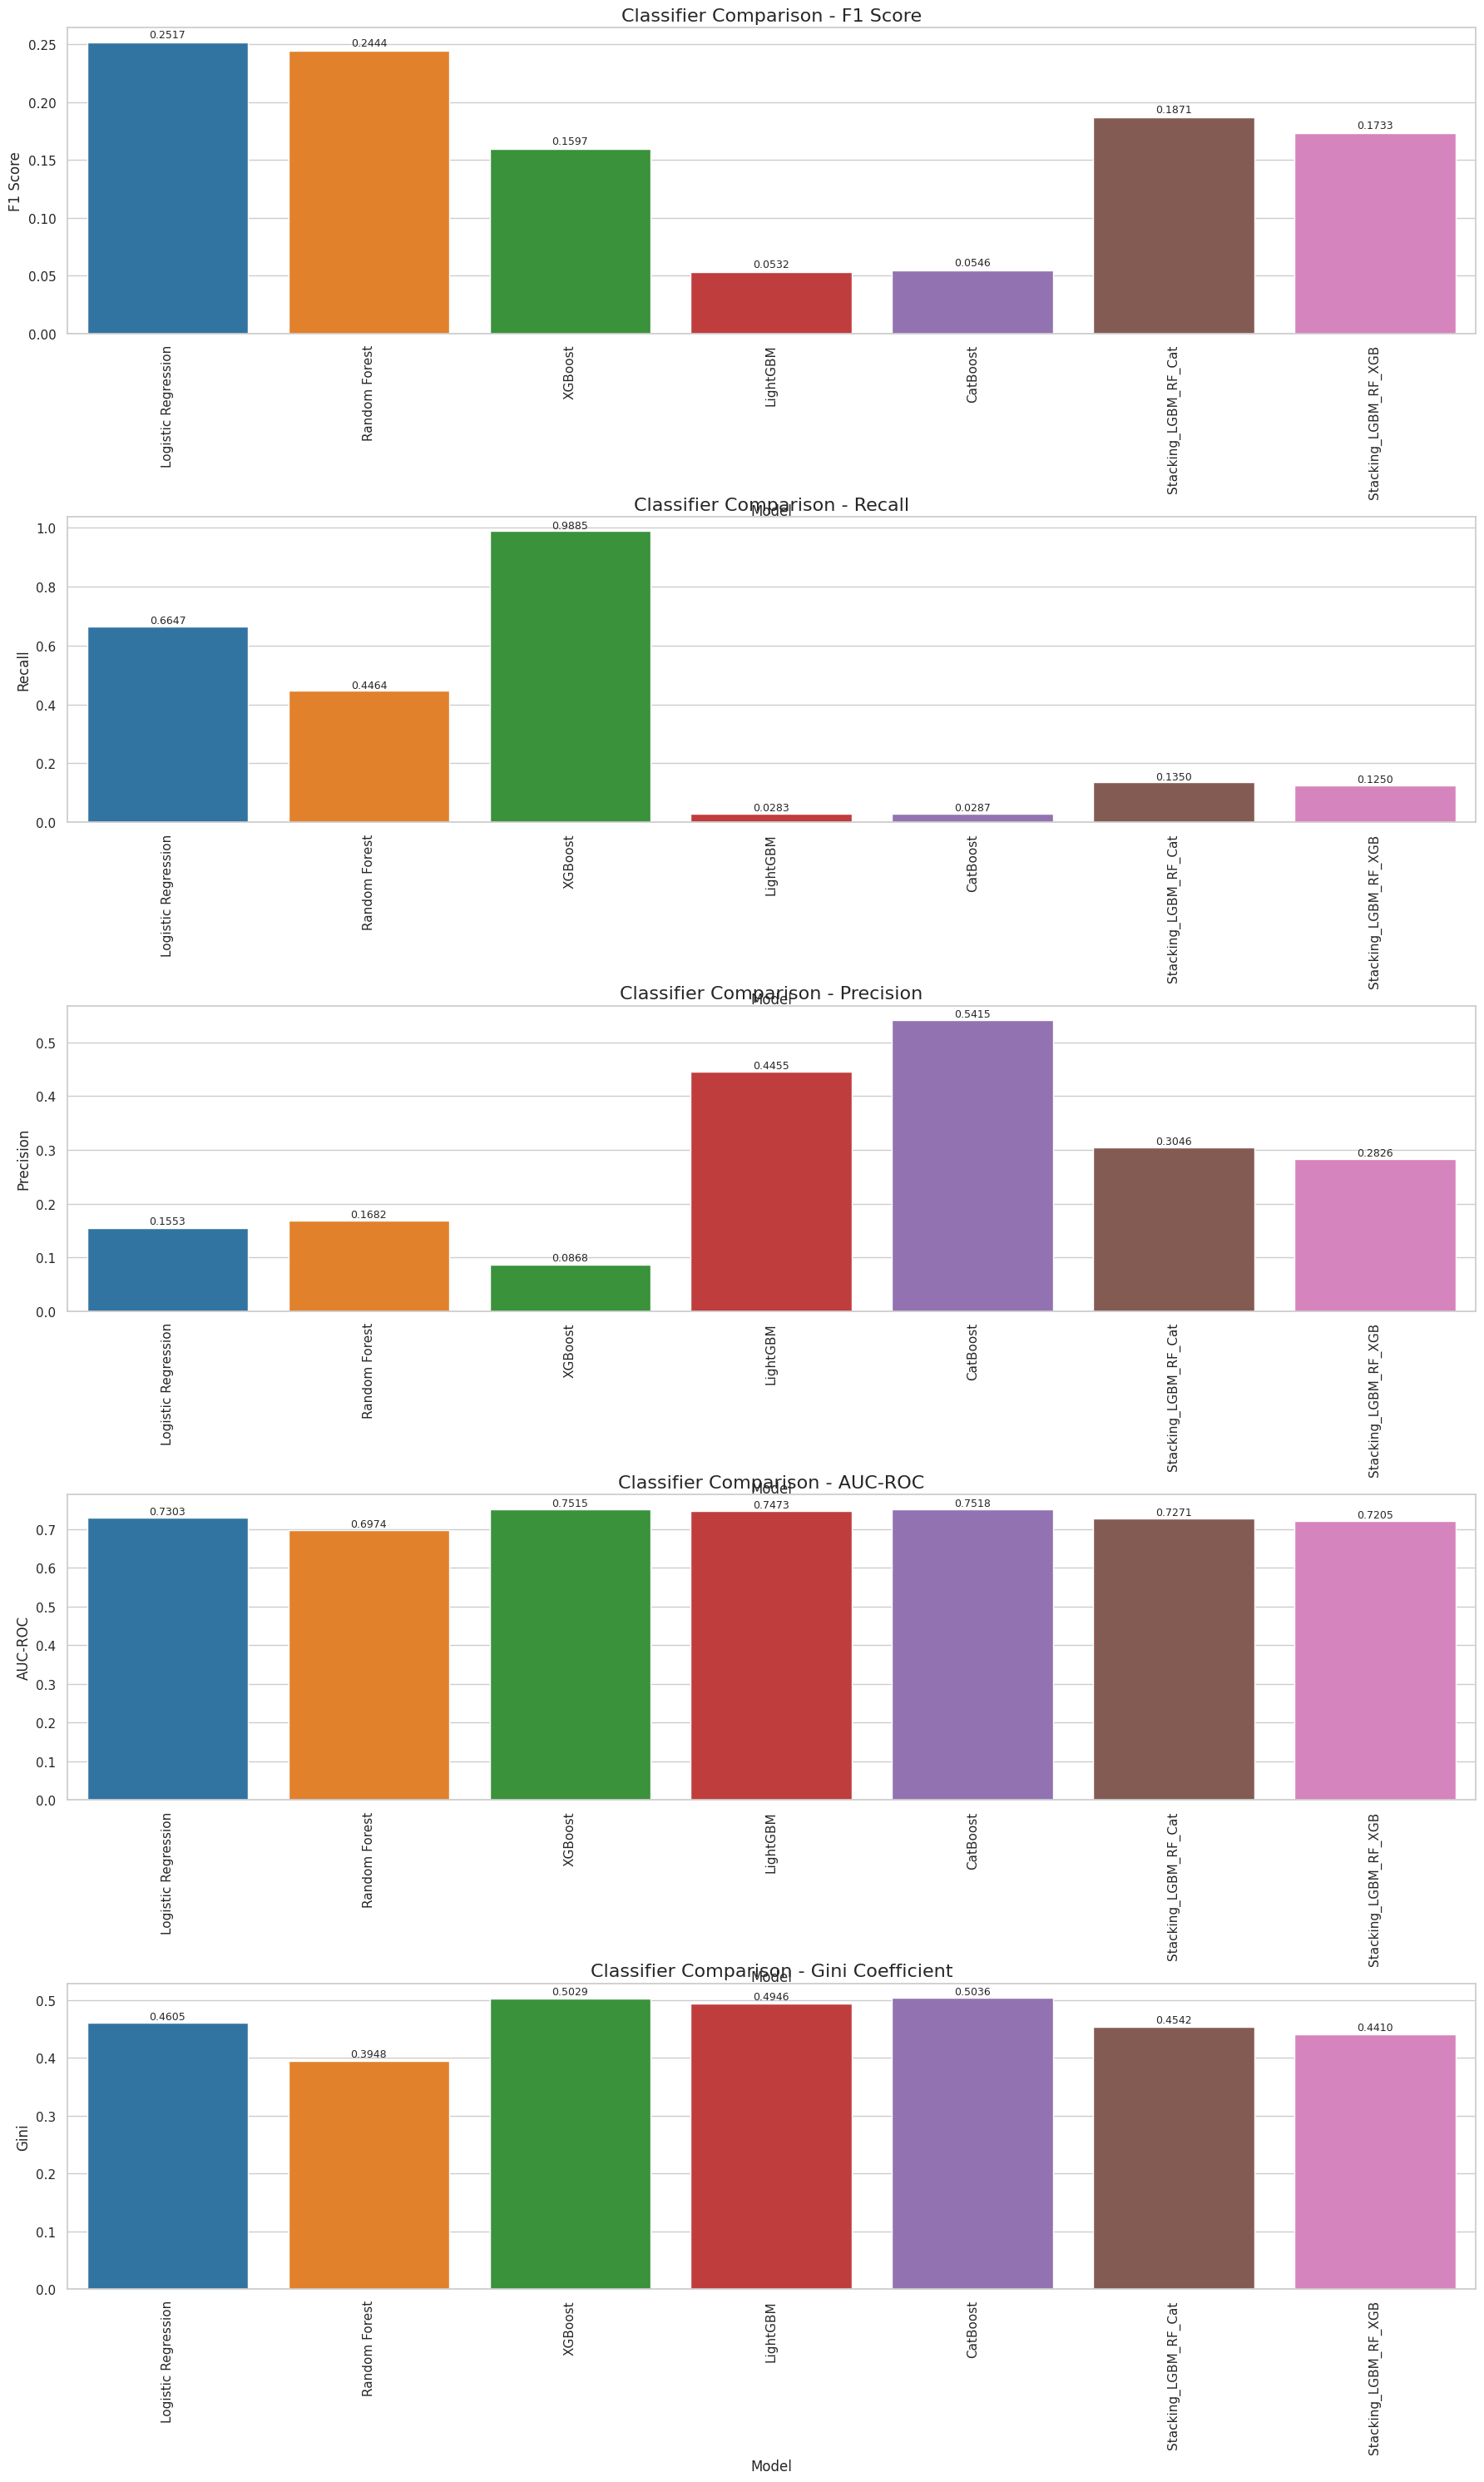

In [ ]:
result_df = pd.DataFrame({
    "Model": model_names,
    "F1 Score": f1_scores,
    "Recall": recall_scores,
    "Precision": precision_scores,
    "AUC-ROC": auc_scores,
    "Gini": gini_scores
})

# Palette màu riêng biệt cho từng model
palette = sns.color_palette("tab10", n_colors=len(result_df))

sns.set(style="whitegrid")
plt.figure(figsize=(18, 30))

# Hàm vẽ từng chỉ số
def plot_metric(ax, metric_name, values, title):
    bars = sns.barplot(x=result_df["Model"], y=values, ax=ax, palette=palette)
    ax.set_title(title, fontsize=16)
    ax.set_ylabel(metric_name)
    ax.set_xticklabels(bars.get_xticklabels(), rotation=90)
    for i, v in enumerate(values):
        ax.text(i, v + 0.002, f"{v:.4f}", ha='center', va='bottom', fontsize=9)

# Vẽ từng biểu đồ
ax1 = plt.subplot(511)
plot_metric(ax1, "F1 Score", result_df["F1 Score"], "Classifier Comparison - F1 Score")

ax2 = plt.subplot(512)
plot_metric(ax2, "Recall", result_df["Recall"], "Classifier Comparison - Recall")

ax3 = plt.subplot(513)
plot_metric(ax3, "Precision", result_df["Precision"], "Classifier Comparison - Precision")

ax4 = plt.subplot(514)
plot_metric(ax4, "AUC-ROC", result_df["AUC-ROC"], "Classifier Comparison - AUC-ROC")

ax5 = plt.subplot(515)
plot_metric(ax5, "Gini", result_df["Gini"], "Classifier Comparison - Gini Coefficient")

plt.tight_layout()
plt.subplots_adjust(hspace=0.6)
plt.show()

In [ ]:
result_df.sort_values("AUC-ROC", ascending=False).reset_index(drop=True)


,Model,F1 Score,Recall,Precision,AUC-ROC,Gini
0,CatBoost,0.054560,0.028727,0.541502,0.751814,0.503629
1,XGBoost,0.159656,0.988467,0.086841,0.751456,0.502912
2,LightGBM,0.053233,0.028308,0.445545,0.747304,0.494609
3,Logistic Regression,0.251717,0.664710,0.155255,0.730262,0.460524
4,Stacking_LGBM_RF_Cat,0.187128,0.135039,0.304636,0.727093,0.454187
5,Stacking_LGBM_RF_XGB,0.173306,0.124974,0.282598,0.720511,0.441022
6,Random Forest,0.244362,0.446425,0.168221,0.697410,0.394819


###  Nhận xét nhanh:

-  **XGBoost** đạt **Recall gần như tuyệt đối (0.99)**, phù hợp nếu ưu tiên phát hiện hết các trường hợp vỡ nợ.  
   Tuy nhiên, Precision rất thấp → cảnh báo nhầm nhiều → F1 Score chỉ ở mức trung bình.

-  **Logistic Regression** và **Random Forest** có **F1 Score cao nhất (~0.25)**, cho thấy cân bằng tốt giữa **Recall và Precision**.  
  → Phù hợp với mục tiêu tổng thể, đặc biệt khi yêu cầu mô hình **đơn giản, dễ triển khai và giải thích (XAI)**.

-  **LightGBM** và **CatBoost** có F1 Score rất thấp dù AUC-ROC cao → cho thấy mô hình bị mất cân bằng thực sự, **SMOTE chưa cải thiện được đáng kể**.

-  **Stacking models** chưa đem lại hiệu quả vượt trội:  
  F1 Score vẫn thua Logistic/Random Forest → có thể do tổ hợp mô hình không tăng thêm sức mạnh trong setup hiện tại.

###  Kết luận:

- **Logistic Regression** và **Random Forest** là lựa chọn hợp lý nhất hiện tại với F1 Score cao, ổn định, dễ triển khai và hỗ trợ XAI.
- **XGBoost** có thể dùng nếu chấp nhận hy sinh Precision để **tăng khả năng phát hiện rủi ro cao nhất**.
- Các mô hình ensemble (Stacking) cần cải thiện thêm để đạt hiệu quả rõ ràng hơn.

### Choose Best Performing Model

### Save model

In [ ]:
# Thư mục lưu
save_dir = "/content/drive/MyDrive/KhoaLuan/"
os.makedirs(save_dir, exist_ok=True)

# Lưu từng model
for name, model in models:  # models phải là list [(name, model)]
    file_path = os.path.join(save_dir, f"{name.replace(' ', '_')}.pkl")
    try:
        joblib.dump(model, file_path)
        print(f"✅ Đã lưu: {file_path}")
    except Exception as e:
        print(f"❌ Lỗi khi lưu {name}: {e}")


✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Logistic_Regression.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Random_Forest.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/XGBoost.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/LightGBM.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/CatBoost.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Stacking_LGBM_RF_Cat.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Stacking_LGBM_RF_XGB.pkl
✅ Đã lưu: /content/drive/MyDrive/KhoaLuan/Voting_LGBM_RF_Cat.pkl
